# MA 310 Project: Parameter-Efficient Fine-Tuning with LoRA on DINOv2
### Low-Rank Adaptation vs Full Fine-Tuning on Oxford-IIIT Pet Dataset

In [ ]:
!pip install evaluate peft transformers datasets torch torchvision scikit-learn matplotlib seaborn -q

## Imports & Configuration

In [ ]:
from typing import Any, Dict, Tuple
from datasets import ClassLabel, load_dataset
import evaluate
import gc
import math
import random
import time
import matplotlib.pyplot as plt
import numpy as np
from peft import LoraConfig, get_peft_model
import seaborn as sns
from sklearn.metrics import confusion_matrix
import torch
from torchvision.transforms import (
    CenterCrop,
    Compose,
    Normalize,
    RandomHorizontalFlip,
    RandomResizedCrop,
    Resize,
    ToTensor,
)
from transformers import (
    AutoImageProcessor,
    AutoModelForImageClassification,
    Trainer,
    TrainingArguments,
)

# ==========================================
# Configuration
# ==========================================
MODEL_CHECKPOINT = "facebook/dinov2-small"  # Vision Transformer, self-supervised
DATASET_NAME = "visual-layer/oxford-iiit-pet-vl-enriched"
BATCH_SIZE = 32
NUM_EPOCHS_LORA = 5
NUM_EPOCHS_BASE = 10
SEED = 42
VAL_SPLIT_RATIO = 0.15  # 15% of train split held out for validation

# LoRA rank ablation values
LORA_RANKS = [4, 8, 16]


def set_seed(seed: int):
    """Ensures reproducible results across runs by resetting all RNG states."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


set_seed(SEED)
print(f"Using device: {'cuda' if torch.cuda.is_available() else 'cpu'}")

Using device: cuda


## Data Loading, Stratified Train/Val/Test Split & Augmentation
To prevent **data leakage**, we split the original `train` split (3,680 images) into an **85% Training set** and a **15% Validation set** using stratified sampling across all 37 pet breeds. The `test` set (3,669 images) is strictly held out for final evaluation.

Furthermore, we apply **Data Augmentation** (`RandomResizedCrop`, `RandomHorizontalFlip`) to `train_ds` to regularize training and prevent rapid memorization, while keeping deterministic `Resize` + `CenterCrop` for `val_ds` and `test_ds`.

In [ ]:
print("Loading dataset and processor...")
raw_dataset = load_dataset(DATASET_NAME)

# Extract sorted unique breed labels
labels = sorted(list(set(raw_dataset["train"]["label_breed"])))
label2id = {label: i for i, label in enumerate(labels)}
id2label = {i: label for i, label in enumerate(labels)}
num_classes = len(labels)


# Add an integer 'label' column so HuggingFace can perform a stratified split
def encode_labels(example):
    example["label"] = label2id[example["label_breed"]]
    return example


raw_dataset = raw_dataset.map(encode_labels)
raw_dataset = raw_dataset.cast_column(
    "label", ClassLabel(num_classes=num_classes, names=labels)
)

# Stratified split of the original train set into Train (85%) and Validation (15%)
train_val_split = raw_dataset["train"].train_test_split(
    test_size=VAL_SPLIT_RATIO, stratify_by_column="label", seed=SEED
)

train_raw = train_val_split["train"]
val_raw = train_val_split["test"]
test_raw = raw_dataset["test"]

print(f"Number of classes : {num_classes}")
print(
    f"Train size        : {len(train_raw)} | Val size: {len(val_raw)} | Test size: {len(test_raw)}"
)

# Load DINOv2 Image Processor
processor = AutoImageProcessor.from_pretrained(MODEL_CHECKPOINT, use_fast=True)
size = processor.size["shortest_edge"]
image_mean = processor.image_mean
image_std = processor.image_std

# Augmentation pipeline for training (prevents overfitting)
train_transforms = Compose(
    [
        RandomResizedCrop(size, scale=(0.8, 1.0)),
        RandomHorizontalFlip(p=0.5),
        ToTensor(),
        Normalize(mean=image_mean, std=image_std),
    ]
)

# Deterministic pipeline for validation and testing
eval_transforms = Compose(
    [
        Resize(size),
        CenterCrop(size),
        ToTensor(),
        Normalize(mean=image_mean, std=image_std),
    ]
)


def preprocess_train(examples):
    """Applies stochastic data augmentation to training batches on-the-fly."""
    examples["pixel_values"] = [
        train_transforms(image.convert("RGB")) for image in examples["image"]
    ]
    return examples


def preprocess_eval(examples):
    """Applies deterministic center cropping to validation/test batches on-the-fly."""
    examples["pixel_values"] = [
        eval_transforms(image.convert("RGB")) for image in examples["image"]
    ]
    return examples


train_ds = train_raw.with_transform(preprocess_train)
val_ds = val_raw.with_transform(preprocess_eval)
test_ds = test_raw.with_transform(preprocess_eval)


def collate_fn(examples):
    """Batches pixel values and integer class labels."""
    pixel_values = torch.stack([example["pixel_values"] for example in examples])
    labels_tensor = torch.tensor(
        [example["label"] for example in examples], dtype=torch.long
    )
    return {"pixel_values": pixel_values, "labels": labels_tensor}

Loading dataset and processor...
Number of classes : 37
Train size        : 3128 | Val size: 552 | Test size: 3669


## Metrics

In [ ]:
metric = evaluate.load("accuracy")


def compute_metrics(eval_pred):
    """Calculates top-1 accuracy during the validation/test phase."""
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    return metric.compute(predictions=predictions, references=labels)

In [ ]:
import sys
# Hide the incompatible pre-installed torchao from PEFT's dispatcher
sys.modules["torchao"] = None

## LoRA Experiment

In [ ]:
def run_lora_experiment(
    rank: int = 16, return_trainer: bool = True
) -> Tuple[Any, Dict[str, Any]]:
    """Runs LoRA fine-tuning on DINOv2-small.

    - Injects trainable low-rank matrices A and B into 'query' and 'value'
    projections.
    - Freezes all 22M backbone weights; only trains A, B, and the 37-class
    classifier head.
    - Monitors validation accuracy per epoch and evaluates on the held-out
    test_ds at the end.
    """
    print(f"\n{'='*60}")
    print(f"  Starting LoRA Experiment  (rank r={rank})")
    print(f"{'='*60}")

    set_seed(SEED)
    torch.cuda.empty_cache()
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    model = AutoModelForImageClassification.from_pretrained(
        MODEL_CHECKPOINT,
        num_labels=num_classes,
        id2label=id2label,
        label2id=label2id,
        ignore_mismatched_sizes=True,
    )

    config = LoraConfig(
        r=rank,
        lora_alpha=2 * rank,
        target_modules=["q_proj", "v_proj"], # Updated from ["query", "value"]
        lora_dropout=0.1,
        modules_to_save=["classifier"],
    )
    model = get_peft_model(model, config)
    model.print_trainable_parameters()

    trainable_params = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )
    total_params = sum(p.numel() for p in model.parameters())

    # Calculate explicit warmup_steps (10% of total training steps) to avoid deprecation warning
    steps_per_epoch = math.ceil(len(train_ds) / BATCH_SIZE)
    total_steps = steps_per_epoch * NUM_EPOCHS_LORA
    warmup_steps = int(0.1 * total_steps)

    args = TrainingArguments(
        output_dir=f"./dinov2-lora-r{rank}",
        remove_unused_columns=False,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="accuracy",
        save_total_limit=1,
        learning_rate=1e-3,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        fp16=torch.cuda.is_available(),
        num_train_epochs=NUM_EPOCHS_LORA,
        warmup_steps=warmup_steps,
        weight_decay=0.01,
        lr_scheduler_type="cosine",
        logging_steps=25,
        report_to="none",
        seed=SEED,
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=val_ds,  # Validation set used during training!
        compute_metrics=compute_metrics,
        data_collator=collate_fn,
    )

    print("Starting LoRA training...")
    start_time = time.time()
    trainer.train()
    train_time = time.time() - start_time

    max_memory_mb = 0
    if torch.cuda.is_available():
        max_memory_mb = torch.cuda.max_memory_allocated() / (1024**2)

    # Evaluate on Validation Set (best checkpoint) and Held-Out Test Set
    val_results = trainer.evaluate(eval_dataset=val_ds)
    test_results = trainer.evaluate(eval_dataset=test_ds)

    results_dict = {
        "Mode": f"LoRA (r={rank})",
        "Val Accuracy": f"{val_results['eval_accuracy']*100:.2f}%",
        "Test Accuracy": f"{test_results['eval_accuracy']*100:.2f}%",
        "Train Time (s)": f"{train_time:.2f}",
        "Epochs": NUM_EPOCHS_LORA,
        "Peak VRAM (MB)": (
            f"{max_memory_mb:.2f}" if max_memory_mb > 0 else "N/A (CPU)"
        ),
        "Trainable Params": f"{trainable_params:,}",
        "Total Params": f"{total_params:,}",
        "Trainable %": f"{100 * trainable_params / total_params:.2f}%",
    }

    if not return_trainer:
        del trainer, model
        torch.cuda.empty_cache()
        gc.collect()
        return None, results_dict

    return trainer, results_dict

## Baseline Experiment (Full Fine-Tuning with Differential Learning Rates)

In full fine-tuning we have **two very different kinds of parameters**:

1. **The backbone** (all 22M DINOv2 weights) — these are already well-trained on ImageNet-scale data. If you push them with a large LR, you destroy the learned features (called *catastrophic forgetting*).
2. **The classifier head** — this was randomly initialised (because we changed the number of output classes). It knows nothing yet. It *needs* a large LR to learn in just a few epochs.

Idea is to give the backbone a small LR (`2e-5`) and the classifier a large LR (`1e-3`). PyTorch's `AdamW` supports this via parameter groups — each group can have its own LR.

In [ ]:
def run_baseline_experiment() -> Tuple[Any, Dict[str, Any]]:
    """Runs full fine-tuning (baseline) on DINOv2-small using differential learning rates."""
    print(f"\n{'='*60}")
    print(f"  Starting Baseline Experiment (Full Fine-Tuning)")
    print(f"{'='*60}")

    set_seed(SEED)
    torch.cuda.empty_cache()
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    model = AutoModelForImageClassification.from_pretrained(
        MODEL_CHECKPOINT,
        num_labels=num_classes,
        id2label=id2label,
        label2id=label2id,
        ignore_mismatched_sizes=True,
    )

    trainable_params = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )
    total_params = sum(p.numel() for p in model.parameters())
    print(f"Trainable Parameters: {trainable_params:,} / {total_params:,} (100.00%)")

    # Differential Learning Rates via AdamW parameter groups
    backbone_params = list(model.dinov2.parameters())
    classifier_params = list(model.classifier.parameters())

    optimizer = torch.optim.AdamW(
        [
            {"params": backbone_params, "lr": 2e-5},
            {"params": classifier_params, "lr": 1e-3},
        ],
        weight_decay=0.01,
    )

    steps_per_epoch = math.ceil(len(train_ds) / BATCH_SIZE)
    total_steps = steps_per_epoch * NUM_EPOCHS_BASE
    warmup_steps = int(0.1 * total_steps)

    args = TrainingArguments(
        output_dir="./dinov2-baseline",
        remove_unused_columns=False,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="accuracy",
        save_total_limit=1,
        learning_rate=2e-5,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        fp16=torch.cuda.is_available(),
        num_train_epochs=NUM_EPOCHS_BASE,
        warmup_steps=warmup_steps,
        weight_decay=0.01,
        lr_scheduler_type="cosine",
        logging_steps=25,
        report_to="none",
        seed=SEED,
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=val_ds,  # Validation set used during training!
        compute_metrics=compute_metrics,
        data_collator=collate_fn,
        optimizers=(optimizer, None),
    )

    print("Starting baseline training...")
    start_time = time.time()
    trainer.train()
    train_time = time.time() - start_time

    max_memory_mb = 0
    if torch.cuda.is_available():
        max_memory_mb = torch.cuda.max_memory_allocated() / (1024**2)

    val_results = trainer.evaluate(eval_dataset=val_ds)
    test_results = trainer.evaluate(eval_dataset=test_ds)

    return trainer, {
        "Mode": "Baseline (Full FT)",
        "Val Accuracy": f"{val_results['eval_accuracy']*100:.2f}%",
        "Test Accuracy": f"{test_results['eval_accuracy']*100:.2f}%",
        "Train Time (s)": f"{train_time:.2f}",
        "Epochs": NUM_EPOCHS_BASE,
        "Peak VRAM (MB)": (
            f"{max_memory_mb:.2f}" if max_memory_mb > 0 else "N/A (CPU)"
        ),
        "Trainable Params": f"{trainable_params:,}",
        "Total Params": f"{total_params:,}",
        "Trainable %": "100.00%",
    }

## Run Main Experiments

In [ ]:
lora_trainer, lora_res = run_lora_experiment(rank=16, return_trainer=True)
base_trainer, base_res = run_baseline_experiment()

# Print comparison table
print("\n" + "=" * 78)
print(f"  MAIN RESULTS COMPARISON (Evaluated on Held-Out Test Set)")
print("=" * 78)
print(f"{'Metric':<22} | {'Baseline (Full FT)':<25} | {'LoRA (r=16)':<20}")
print("-" * 78)
for key in [
    "Val Accuracy",
    "Test Accuracy",
    "Train Time (s)",
    "Epochs",
    "Peak VRAM (MB)",
    "Trainable Params",
    "Total Params",
    "Trainable %",
]:
    print(f"{key:<22} | {str(base_res[key]):<25} | {str(lora_res[key]):<20}")
print("=" * 78)


  Starting LoRA Experiment  (rank r=16)


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

[transformers] Dinov2ForImageClassification LOAD REPORT from: facebook/dinov2-small
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 323,365 || all params: 22,408,394 || trainable%: 1.4431
Starting LoRA training...


Epoch,Training Loss,Validation Loss,Accuracy
1,0.430615,0.282991,0.902174
2,0.218028,0.203037,0.927536
3,0.078517,0.154097,0.942029
4,0.022473,0.131016,0.951087
5,0.006761,0.121170,0.963768


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['dinov2.encoder.layer.0.attention.q_proj.weight', 'dinov2.encoder.layer.0.attention.q_proj.bias', 'dinov2.encoder.layer.0.attention.k_proj.weight', 'dinov2.encoder.layer.0.attention.k_proj.bias', 'dinov2.encoder.layer.0.attention.v_proj.weight', 'dinov2.encoder.layer.0.attention.v_proj.bias', 'dinov2.encoder.layer.0.attention.o_proj.weight', 'dinov2.encoder.layer.0.attention.o_proj.bias', 'dinov2.encoder.layer.1.attention.q_proj.weight', 'dinov2.encoder.layer.1.attention.q_proj.bias', 'dinov2.encoder.layer.1.attention.k_proj.weight', 'dinov2.encoder.layer.1.attention.k_proj.bias', 'dinov2.encoder.layer.1.attention.v_proj.weight', 'dinov2.encoder.layer.1.attention.v_proj.bias', 'dinov2.encoder.layer.1.attention.o_proj.weight', 'dinov2.encoder.layer.1.attention.o_proj.bias', 'dinov2.encoder.layer.2.attention.q_proj.weight', 'dinov2.encoder.layer.2.attention.q_proj.bias', 'dinov2.encoder.layer.2.attention.k_proj.weigh

Training Loss,Validation Loss,Epoch,Accuracy
0.000150,0.158973,10,0.954710


Training Loss,Validation Loss,Epoch,Accuracy
0.000150,0.273602,10,0.938948



  MAIN RESULTS COMPARISON (Evaluated on Held-Out Test Set)
Metric                 | Baseline (Full FT)        | LoRA (r=16)         
------------------------------------------------------------------------------
Val Accuracy           | 95.47%                    | 96.38%              
Test Accuracy          | 93.89%                    | 94.41%              
Train Time (s)         | 416.99                    | 198.35              
Epochs                 | 10                        | 5                   
Peak VRAM (MB)         | 2547.46                   | 1644.34             
Trainable Params       | 22,085,029                | 323,365             
Total Params           | 22,085,029                | 22,408,394          
Trainable %            | 100.00%                   | 1.44%               


## Rank Ablation Study

The LoRA paperclaims that a very low rank (r=2 or r=4) is sufficient
because weight updates during adaptation have a low intrinsic rank.
We verify this by training with r = 4, 8, 16 and comparing accuracy.

In [ ]:
ablation_results = []

for r in LORA_RANKS:
    if r == 16:
        # Reuse the already-trained r=16 result to save ~6 mins of GPU compute
        res = lora_res
    else:
        _, res = run_lora_experiment(rank=r, return_trainer=False)
    ablation_results.append(res)
    print(
        f"  r={r:>2}  →  Val Acc: {res['Val Accuracy']}  |  Test Acc: {res['Test Accuracy']}  |  Trainable: {res['Trainable Params']}"
    )

print("\n" + "=" * 80)
print("  LORA RANK ABLATION SUMMARY")
print("=" * 80)
print(
    f"{'Rank':<8} | {'Val Accuracy':<14} | {'Test Accuracy':<14} | {'Trainable Params':<18} | {'Trainable %'}"
)
print("-" * 80)
for res in ablation_results:
    r_label = res["Mode"].split("r=")[1].rstrip(")")
    print(
        f"{r_label:<8} | {res['Val Accuracy']:<14} | {res['Test Accuracy']:<14} | {res['Trainable Params']:<18} | {res['Trainable %']}"
    )
print("=" * 80)


  Starting LoRA Experiment  (rank r=4)


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

[transformers] Dinov2ForImageClassification LOAD REPORT from: facebook/dinov2-small
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 102,181 || all params: 22,187,210 || trainable%: 0.4605
Starting LoRA training...


Epoch,Training Loss,Validation Loss,Accuracy
1,0.383835,0.280509,0.898551
2,0.147282,0.180544,0.929348
3,0.059071,0.149729,0.945652
4,0.023613,0.128349,0.952899
5,0.010468,0.127720,0.954710


...

trainable params: 175,909 || all params: 22,260,938 || trainable%: 0.7902
Starting LoRA training...


Epoch,Training Loss,Validation Loss,Accuracy
1,0.406167,0.304182,0.894928
2,0.186624,0.195056,0.925725
3,0.070631,0.156012,0.945652
4,0.019871,0.136435,0.956522
5,0.006842,0.136035,0.954710


Training Loss,Validation Loss,Epoch,Accuracy
0.006842,0.136435,5,0.956522


Training Loss,Validation Loss,Epoch,Accuracy
0.006842,0.191868,5,0.946579


  r= 8  →  Val Acc: 95.65%  |  Test Acc: 94.66%  |  Trainable: 175,909
  r=16  →  Val Acc: 96.38%  |  Test Acc: 94.41%  |  Trainable: 323,365

  LORA RANK ABLATION SUMMARY
Rank     | Val Accuracy   | Test Accuracy  | Trainable Params   | Trainable %
--------------------------------------------------------------------------------
4        | 95.47%         | 94.79%         | 102,181            | 0.46%
8        | 95.65%         | 94.66%         | 175,909            | 0.79%
16       | 96.38%         | 94.41%         | 323,365            | 1.44%


## Rank-Deficiency Analysis (Paper Section 4.1)

The LoRA paper hypothesises that the update matrix delta_W = B @ A lies in a
low-rank subspace — i.e., most of the "learning signal" lives in just a few
singular directions. We verify this by computing the Singular Value Decomposition
of B @ A for each LoRA layer and plotting the singular value spectrum.

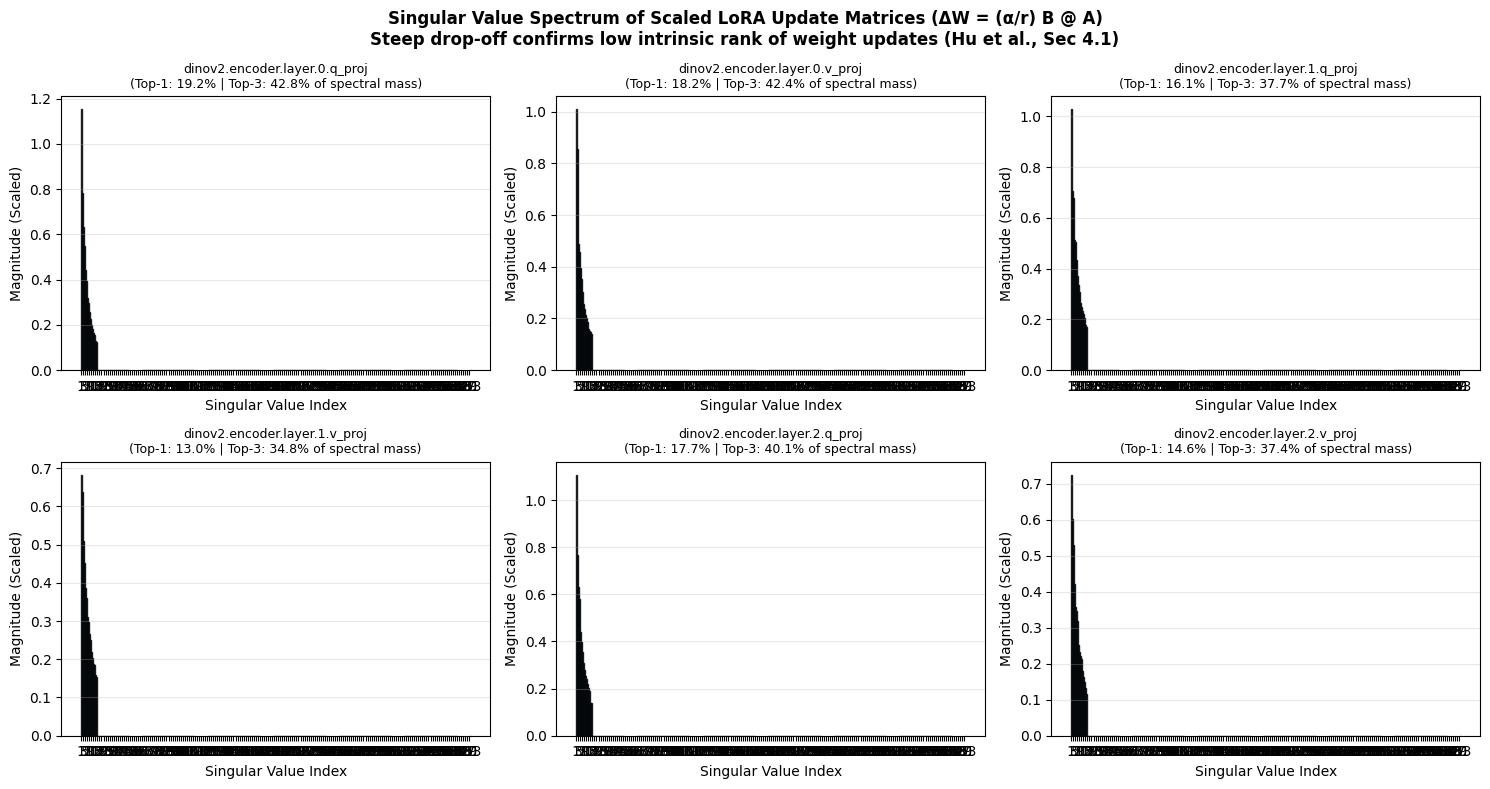

Analysed 24 LoRA layers total.


In [ ]:
def analyse_rank_deficiency(trainer):
    """Computes the scaled update matrix delta_W = (lora_alpha / r) * (B @ A)

    for each LoRA layer and plots its singular value spectrum.
    """
    model = trainer.model
    all_singular_values = []
    layer_names = []

    for name, module in model.named_modules():
        if hasattr(module, "lora_A") and hasattr(module, "lora_B"):
            A = module.lora_A["default"].weight.data  # shape: (r, in_features)
            B = module.lora_B["default"].weight.data  # shape: (out_features, r)

            # Include the PEFT scaling factor (lora_alpha / r) for true update magnitude
            scaling = (
                module.scaling["default"] if hasattr(module, "scaling") else 2.0
            )
            delta_W = (B @ A) * scaling  # shape: (out_features, in_features)

            singular_values = (
                torch.linalg.svdvals(delta_W.float()).cpu().numpy()
            )
            all_singular_values.append(singular_values)

            short_name = name.replace("base_model.model.", "").replace(
                ".attention", ""
            )
            layer_names.append(short_name)

    if not all_singular_values:
        print("No LoRA layers found in model. Run LoRA experiment first.")
        return

    n_plot = min(6, len(all_singular_values))
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    axes = axes.flatten()

    for i in range(n_plot):
        sv = all_singular_values[i]
        axes[i].bar(
            range(1, len(sv) + 1),
            sv,
            color="steelblue",
            alpha=0.85,
            edgecolor="black",
        )
        axes[i].set_xlabel("Singular Value Index")
        axes[i].set_ylabel("Magnitude (Scaled)")
        axes[i].set_xticks(range(1, len(sv) + 1, 2))
        axes[i].grid(axis="y", alpha=0.3)

        top1_pct = (sv[0] / sv.sum()) * 100
        top3_pct = (sv[:3].sum() / sv.sum()) * 100
        axes[i].set_title(
            f"{layer_names[i]}\n(Top-1: {top1_pct:.1f}% | Top-3: {top3_pct:.1f}% of spectral mass)",
            fontsize=9,
        )

    plt.suptitle(
        "Singular Value Spectrum of Scaled LoRA Update Matrices (ΔW = (α/r) B @ A)\n"
        "Steep drop-off confirms low intrinsic rank of weight updates (Hu et al., Sec 4.1)",
        fontsize=12,
        fontweight="bold",
    )
    plt.tight_layout()
    plt.savefig("rank_deficiency_analysis.png", dpi=200)
    plt.show()
    print(f"Analysed {len(all_singular_values)} LoRA layers total.")


analyse_rank_deficiency(lora_trainer)

## Training Curves

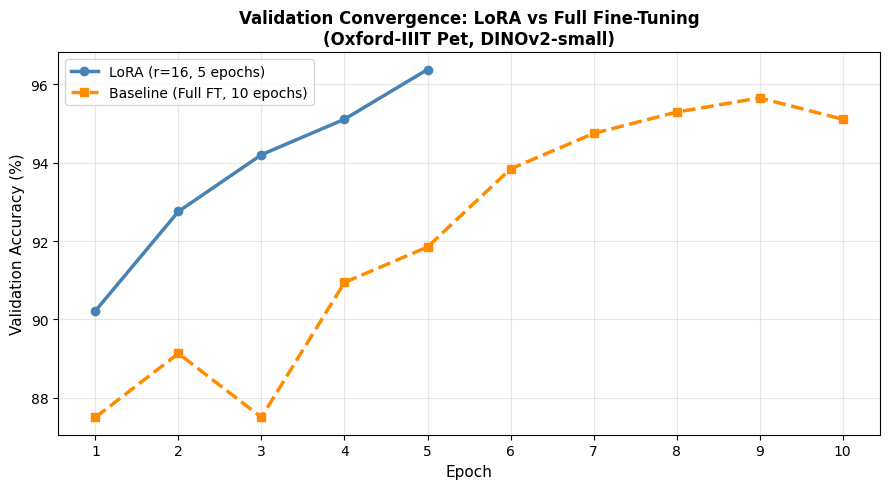

In [ ]:
def plot_training_curves(lora_trainer, base_trainer):
    """Plots per-epoch validation accuracy for LoRA vs Baseline."""

    def extract_epoch_eval_accuracy(trainer):
        # Extract only epoch-level validation logs (exclude final test evaluation log)
        accs = [
            entry["eval_accuracy"]
            for entry in trainer.state.log_history
            if "eval_accuracy" in entry
        ]
        num_epochs = int(trainer.args.num_train_epochs)
        return accs[:num_epochs]

    lora_acc = extract_epoch_eval_accuracy(lora_trainer)
    base_acc = extract_epoch_eval_accuracy(base_trainer)

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(
        range(1, len(lora_acc) + 1),
        [a * 100 for a in lora_acc],
        "o-",
        label=f"LoRA (r=16, {NUM_EPOCHS_LORA} epochs)",
        color="steelblue",
        linewidth=2.5,
    )
    ax.plot(
        range(1, len(base_acc) + 1),
        [a * 100 for a in base_acc],
        "s--",
        label=f"Baseline (Full FT, {NUM_EPOCHS_BASE} epochs)",
        color="darkorange",
        linewidth=2.5,
    )

    ax.set_xlabel("Epoch", fontsize=11)
    ax.set_ylabel("Validation Accuracy (%)", fontsize=11)
    ax.set_title(
        "Validation Convergence: LoRA vs Full Fine-Tuning\n(Oxford-IIIT Pet, DINOv2-small)",
        fontsize=12,
        fontweight="bold",
    )
    ax.set_xticks(range(1, max(len(lora_acc), len(base_acc)) + 1))
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("training_curves.png", dpi=200)
    plt.show()


plot_training_curves(lora_trainer, base_trainer)

## Full 37x37 Confusion Matrix & Top-5 Most Confused Breed Pairs
We evaluate on the held-out `test_ds` and generate both:
1. **The Full 37x37 Confusion Matrix Heatmap** for both LoRA and Baseline.
2. **A Top-5 Most Confused Breed Pairs Analysis** to pinpoint exact fine-grained failure modes.


Generating Predictions & Confusion Matrix for LoRA DINOv2 (r=16)...


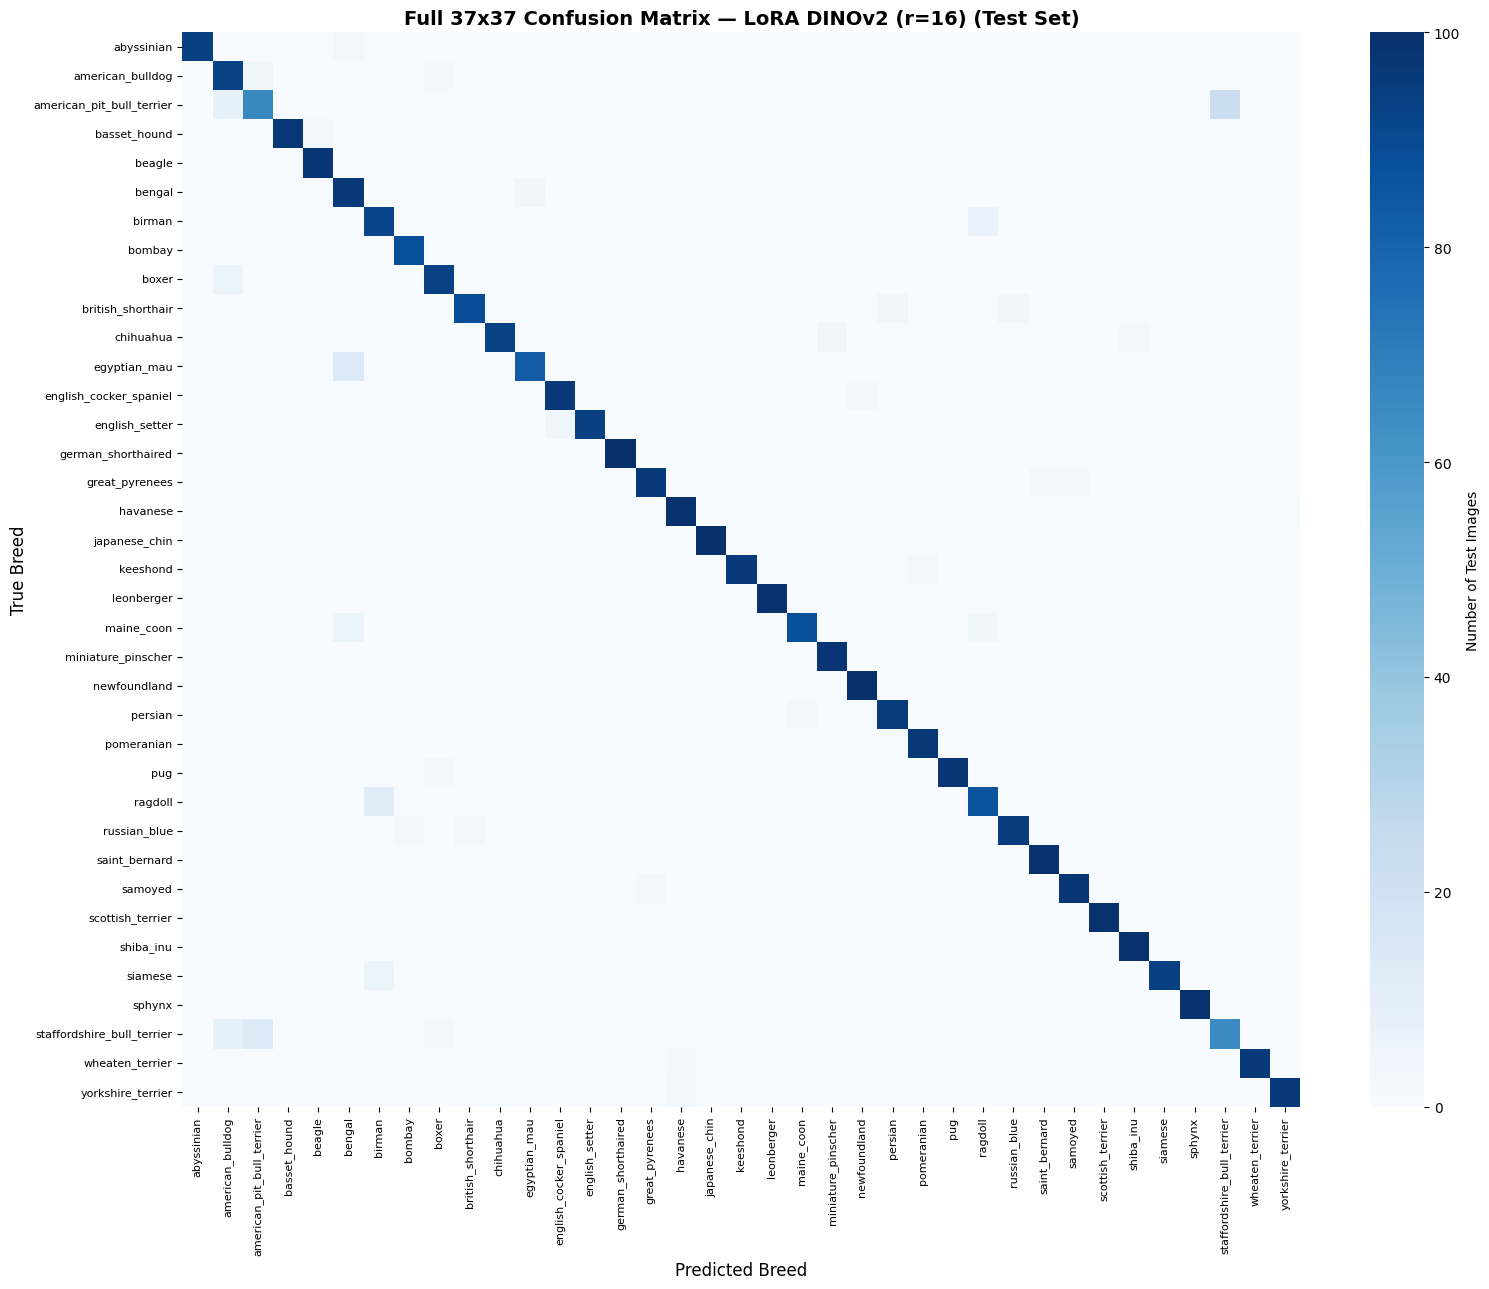


Top 5 Most Confused Breed Pairs (LoRA DINOv2 (r=16)):
---------------------------------------------------------------------------
Rank   | True Breed                   | Predicted As                 | Count
---------------------------------------------------------------------------
#1     | american_pit_bull_terrier    | staffordshire_bull_terrier   | 23
#2     | staffordshire_bull_terrier   | american_pit_bull_terrier    | 14
#3     | egyptian_mau                 | bengal                       | 14
#4     | ragdoll                      | birman                       | 12
#5     | american_pit_bull_terrier    | american_bulldog             | 8
---------------------------------------------------------------------------

Generating Predictions & Confusion Matrix for Baseline DINOv2 (Full FT)...


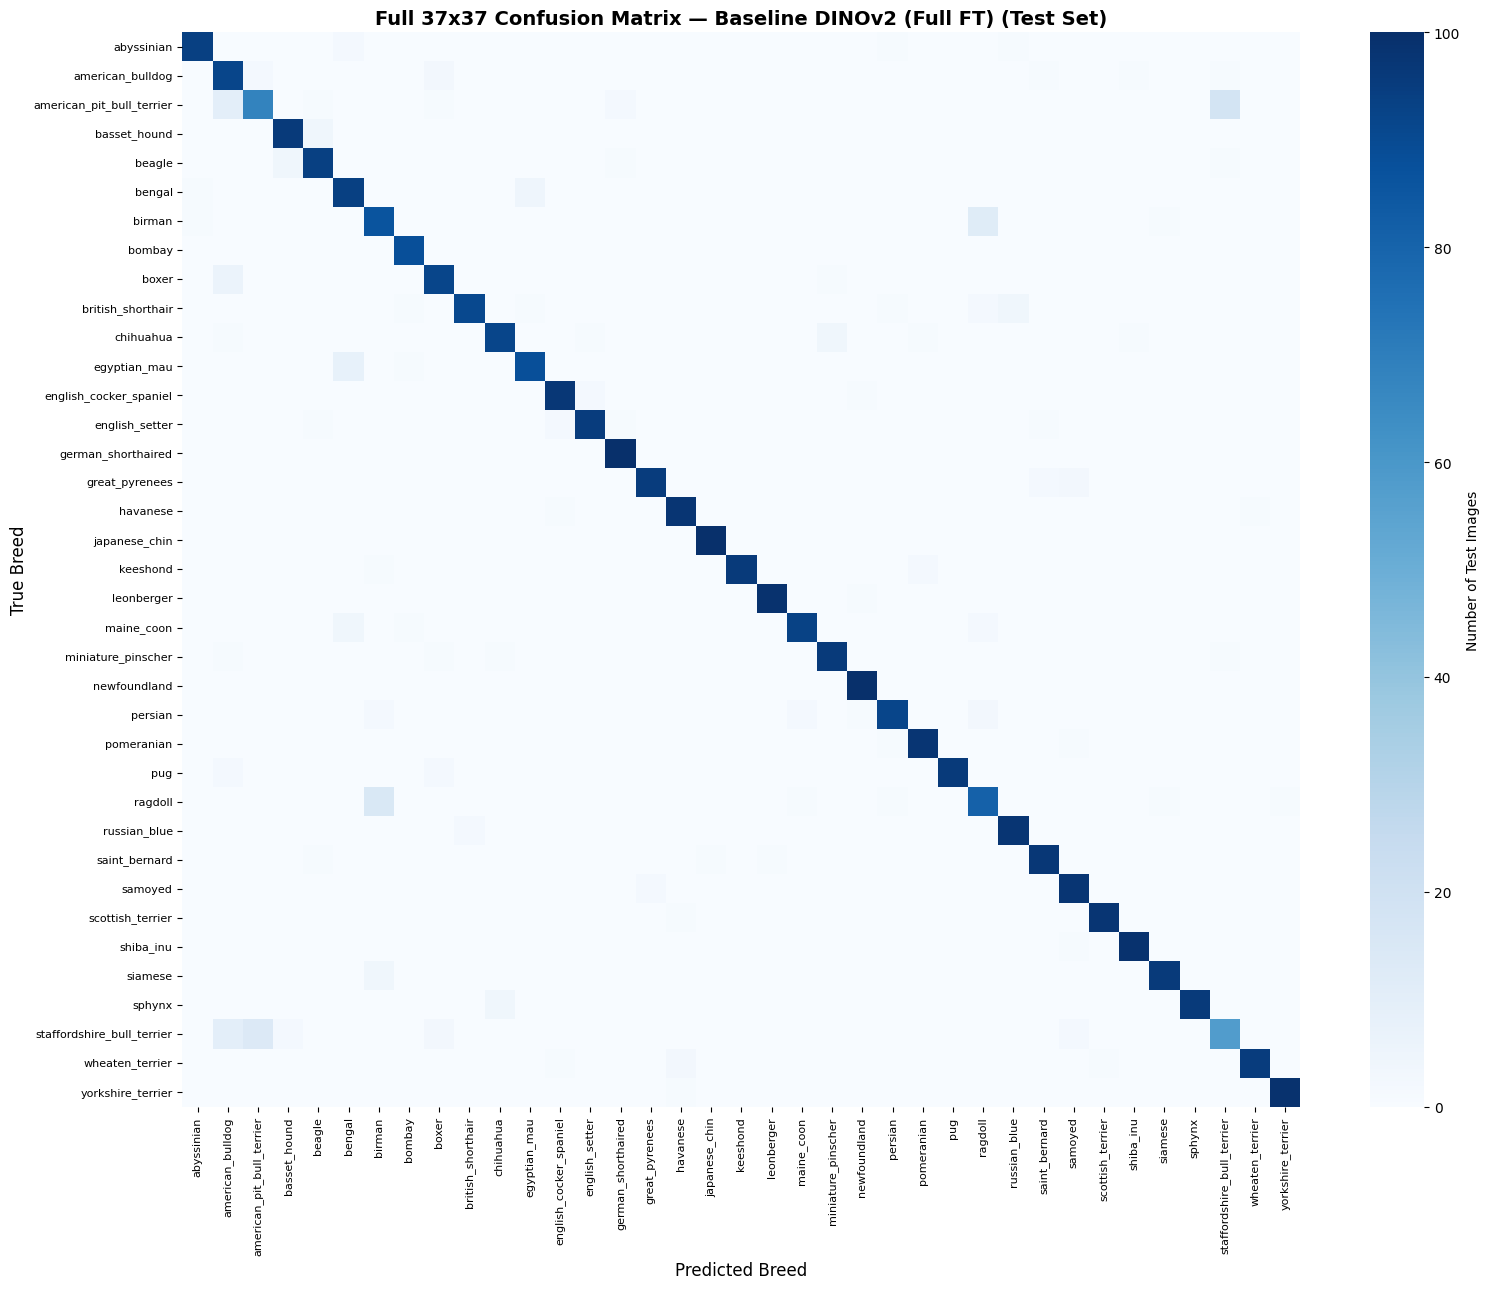


Top 5 Most Confused Breed Pairs (Baseline DINOv2 (Full FT)):
---------------------------------------------------------------------------
Rank   | True Breed                   | Predicted As                 | Count
---------------------------------------------------------------------------
#1     | american_pit_bull_terrier    | staffordshire_bull_terrier   | 18
#2     | ragdoll                      | birman                       | 15
#3     | staffordshire_bull_terrier   | american_pit_bull_terrier    | 14
#4     | birman                       | ragdoll                      | 12
#5     | american_pit_bull_terrier    | american_bulldog             | 10
---------------------------------------------------------------------------


In [ ]:
def evaluate_confusion_matrix_and_top_errors(
    trainer, dataset, title: str, filename: str, top_k: int = 5
):
    """1. Plots the full 37x37 Confusion Matrix on the held-out test dataset.

    2. Extracts and prints the Top-K most frequently confused pet breed pairs.
    """
    print(f"\nGenerating Predictions & Confusion Matrix for {title}...")
    outputs = trainer.predict(dataset)
    y_true = outputs.label_ids
    y_pred = np.argmax(outputs.predictions, axis=1)

    cm = confusion_matrix(y_true, y_pred)

    # 1. Plot Full 37x37 Confusion Matrix
    plt.figure(figsize=(16, 13))
    sns.heatmap(
        cm,
        annot=False,
         cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        cbar_kws={"label": "Number of Test Images"},
    )
    plt.title(
        f"Full 37x37 Confusion Matrix — {title} (Test Set)",
        fontsize=14,
        fontweight="bold",
    )
    plt.xlabel("Predicted Breed", fontsize=12)
    plt.ylabel("True Breed", fontsize=12)
    plt.xticks(rotation=90, fontsize=8)
    plt.yticks(rotation=0, fontsize=8)
    plt.tight_layout()
    plt.savefig(filename, dpi=200)
    plt.show()

    # 2. Extract Top-K Most Confused Breed Pairs (off-diagonal entries)
    cm_off_diag = cm.copy()
    np.fill_diagonal(cm_off_diag, 0)

    # Flatten indices and sort by highest error count
    flat_indices = np.argsort(cm_off_diag.ravel())[::-1][:top_k]
    row_indices, col_indices = np.unravel_index(flat_indices, cm_off_diag.shape)

    print(f"\nTop {top_k} Most Confused Breed Pairs ({title}):")
    print("-" * 75)
    print(f"{'Rank':<6} | {'True Breed':<28} | {'Predicted As':<28} | {'Count'}")
    print("-" * 75)
    for rank_idx, (r, c) in enumerate(zip(row_indices, col_indices), start=1):
        count = cm_off_diag[r, c]
        if count > 0:
            print(f"#{rank_idx:<5} | {id2label[r]:<28} | {id2label[c]:<28} | {count}")
    print("-" * 75)


# Run for both LoRA and Baseline on Held-Out Test Set
evaluate_confusion_matrix_and_top_errors(
    lora_trainer,
    test_ds,
    title="LoRA DINOv2 (r=16)",
    filename="cm_lora_r16.png",
    top_k=5,
)

evaluate_confusion_matrix_and_top_errors(
    base_trainer,
    test_ds,
    title="Baseline DINOv2 (Full FT)",
    filename="cm_baseline_full_ft.png",
    top_k=5,
)

## Final Summary Table

In [ ]:
print(
"\n" + "="*95
)
print("  FINAL SUMMARY")
print("="*95)
print(f"{'Metric':<22} | {'Baseline (Full FT)':<25} | {'LoRA (r=16)':<20}")
print("-" * 95)
for key in ["Val Accuracy", "Test Accuracy", "Train Time (s)", "Epochs", "Peak VRAM (MB)",
            "Trainable Params", "Total Params", "Trainable %"]:
    print(f"{key:<22} | {base_res.get(key, 'N/A'):<25} | {lora_res.get(key, 'N/A'):<20}")
print("="*95)

print("\nRank Ablation (LoRA):")
print(f"{'Rank':<8} | {'Val Accuracy':<14} | {'Test Accuracy':<14} | {'Trainable Params':<20} | Trainable %")
print("-" * 80)
for res in ablation_results:
    r_label = res['Mode'].split('r=')[1].rstrip(')')
    print(f"{r_label:<8} | {res.get('Val Accuracy', 'N/A'):<14} | {res.get('Test Accuracy', 'N/A'):<14} | {res['Trainable Params']:<20} | {res['Trainable %']}")


  FINAL SUMMARY
Metric                 | Baseline (Full FT)        | LoRA (r=16)         
-----------------------------------------------------------------------------------------------
Val Accuracy           | 95.47%                    | 96.38%              
Test Accuracy          | 93.89%                    | 94.41%              
Train Time (s)         | 416.99                    | 198.35              
Epochs                 | 10                        | 5                   
Peak VRAM (MB)         | 2547.46                   | 1644.34             
Trainable Params       | 22,085,029                | 323,365             
Total Params           | 22,085,029                | 22,408,394          
Trainable %            | 100.00%                   | 1.44%               

Rank Ablation (LoRA):
Rank     | Val Accuracy   | Test Accuracy  | Trainable Params     | Trainable %
--------------------------------------------------------------------------------
4        | 95.47%         | 94.79%   